# Analyse Exploratoire des Donnees (EDA)
## Dataset: Individual Household Electric Power Consumption
### UCI Machine Learning Repository - ID: 235

**Periode:** Decembre 2006 - Novembre 2010 (4 ans de donnees)

**Objectifs:**
1. Collecter et charger le dataset
2. Nettoyer les donnees (valeurs manquantes, doublons, outliers)
3. Explorer les statistiques descriptives
4. Visualiser les distributions et correlations
5. Analyser les patterns temporels
6. Produire un dataset propre final
AUTEUR : ENANGA DANIEL CHRISTIAN
 annee - academique : 2025 - 2026


## Etape 0: Imports des bibliotheques

In [1]:
import os
import urllib.request
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
warnings.filterwarnings('ignore') #supprime les averissement pour un affichage plus propre

plt.style.use('seaborn-v0_8-whitegrid') #Applique le style  épuré avec grille
sns.set_palette('husl') # definit la palette de couleurs harmonieuse pour les graphiques
matplotlib.rcParams['figure.dpi'] = 300 # définit la résolution des figures à 300 points par pouce
matplotlib.rcParams['savefig.dpi'] = 600 # définit la résolution des images sauvegardées à 600 points par pouce
plt.figure(figsize=(10, 6))

print("Bibliothèques chargées avec succès!")

Bibliothèques chargées avec succès!


<Figure size 3000x1800 with 0 Axes>

## Etape 1: Telechargement du Dataset depuis l'UCI

Le dataset est disponible sur l'UCI Machine Learning Repository. Nous le telechargeons automatiquement s'il n'est pas deja present.

In [2]:
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "..")) # Chemin vers la racine du projet (tfc)
DATASET_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip" # URL du dataset pour le telechargement 
DATA_DIR = os.path.join(BASE_DIR, "data", "raw" , "uci") # Dossier de donnees brutes
RAW_FILENAME = "household_power_consumption.txt" # Nom du fichier de donnees brutes

os.makedirs(DATA_DIR, exist_ok=True) # Creer le dossier de données si il n'existe pas

raw_path = os.path.join(DATA_DIR, RAW_FILENAME) # Chemin complet vers le fichier de donnees brutes

# Telecharger si necessaire
if not os.path.exists(raw_path):
    print("Telechargement du dataset en cours...")

    zip_path = os.path.join(DATA_DIR, "dataset.zip")
    urllib.request.urlretrieve(DATASET_URL, zip_path)

    print("Extraction de l'archive...")
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(DATA_DIR)
    os.remove(zip_path)
    print("Dataset telechargé et extrait avec succès!")
else:
    print("Le Dataset est déjà présent localement.")
# Verification
for f in os.listdir(DATA_DIR):
    print(f"  -> {f}")

Le Dataset est déjà présent localement.
  -> household_power_consumption.txt


## Etape 2: Chargement des Donnees

Le fichier source utilise `;` comme separateur et `?` pour coder les valeurs manquantes. Nous specifions ces parametres au chargement.

In [3]:
# Chargement du dataset
# na_values=['?'] est CRITIQUE: le dataset utilise '?' pour les valeurs manquantes
df = pd.read_csv(
    raw_path,
    sep=';', # le séparateur dans le dataset est ';'
    na_values=['?', 'nan', 'NaN', ''], # valeurs manquantes représentées par '?', 'nan', 'NaN' ou ''
    low_memory=True #pour optimiser la mémoire lors du chargement du dataset
)
# les données sont chargées dans un DataFrame pandas nommé df. Le paramètre low_memory=True permet de réduire l'utilisation de la mémoire lors du chargement du dataset, ce qui est utile pour les grands fichiers.
print("DATASET CHARGEMENT")
print(f"Dimensions: {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Colonnes: {df.columns.tolist()}")
print(f"Types de données:")
print(df.dtypes)

DATASET CHARGEMENT
Dimensions: 2,075,259 lignes x 9 colonnes
Colonnes: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
Types de données:
Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


### Apercu des premieres lignes

In [4]:
df.head(15)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
5,16/12/2006,17:29:00,3.520,0.522,235.02,15.0,0.0,2.0,17.0
6,16/12/2006,17:30:00,3.702,0.520,235.09,15.8,0.0,1.0,17.0
7,16/12/2006,17:31:00,3.700,0.520,235.22,15.8,0.0,1.0,17.0
8,16/12/2006,17:32:00,3.668,0.510,233.99,15.8,0.0,1.0,17.0
9,16/12/2006,17:33:00,3.662,0.510,233.86,15.8,0.0,2.0,16.0


### Conversion des dates et verification de la periode

In [5]:
# Creer une colonne DateTime pour l'analyse temporelle
df['DateTime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

print(f"Date de debut: {df['DateTime'].min()}")
print(f"Date de fin:   {df['DateTime'].max()}")
print(f"Duree totale:  {df['DateTime'].max() - df['DateTime'].min()}")
print(f"Nombre total d'heures: {len(df) / 60:.0f}")
print(f"Nombre total de jours:   {len(df) / 1440:.0f}")

Date de debut: 2006-12-16 17:24:00
Date de fin:   2010-11-26 21:02:00
Duree totale:  1441 days 03:38:00
Nombre total d'heures: 34588
Nombre total de jours:   1441


## Etape 3: Analyse des Valeurs Manquantes

Identifions le nombre, la proportion et le **pattern** des valeurs manquantes. Un pattern concomitant (toutes les variables numeriques manquantes en meme temps) indiquerait une panne d'equipement.

In [6]:
# Colonnes numeriques se trouvant dans le dataset
numeric_cols = [
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]

print("VALEURS MANQUANTES PAR COLONNE")
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(4)

for col in df.columns:
    if missing_counts[col] > 0:
        print(f"  {col:25s}: {missing_counts[col]:>10,}  ({missing_pct[col]:.2f}%)")
    else:
        print(f"  {col:25s}: {missing_counts[col]:>10,}  (0.00%)")

# Vérifier si les manquants sont concomitants
numeric_missing = df[numeric_cols].isnull()
all_same_missing = numeric_missing.all(axis=1).sum()
total_missing_rows = df[numeric_cols[0]].isnull().sum()

print(f"--- Pattern ---")
print(f"Lignes avec manquants:{total_missing_rows:,}")
print(f"Lignes avec TOUS numeriques manquants: {all_same_missing:,}")
print(f"Pattern concomitant: {'OUI ✓' if all_same_missing == total_missing_rows else 'NON'}")

VALEURS MANQUANTES PAR COLONNE
  Date                     :          0  (0.00%)
  Time                     :          0  (0.00%)
  Global_active_power      :     25,979  (1.25%)
  Global_reactive_power    :     25,979  (1.25%)
  Voltage                  :     25,979  (1.25%)
  Global_intensity         :     25,979  (1.25%)
  Sub_metering_1           :     25,979  (1.25%)
  Sub_metering_2           :     25,979  (1.25%)
  Sub_metering_3           :     25,979  (1.25%)
  DateTime                 :          0  (0.00%)
--- Pattern ---
Lignes avec manquants:25,979
Lignes avec TOUS numeriques manquants: 25,979
Pattern concomitant: OUI ✓


### Distribution temporelle des valeurs manquantes

In [7]:
# Identifier les jours avec des valeurs manquantes
df_temp = df.copy()
df_temp['has_missing'] = df_temp['Global_active_power'].isnull()

missing_rows = df_temp[df_temp['has_missing']]
if len(missing_rows) > 0:
    missing_by_date = missing_rows.groupby(missing_rows['DateTime'].dt.date).size()
    print(f"Nombre de jours avec manquants: {len(missing_by_date)}")
    print(f"Top 10 jours avec le plus de manquants:")
    print(missing_by_date.sort_values(ascending=False).head(10))

    print(f"Date range des manquants: {missing_by_date.index.min()} au {missing_by_date.index.max()}")
    print(f"Max manquants sur un jour: {missing_by_date.max()} minutes ({missing_by_date.max()/60:.1f} heures)")

Nombre de jours avec manquants: 82
Top 10 jours avec le plus de manquants:
DateTime
2007-04-29    1440
2009-06-14    1440
2010-01-13    1440
2010-08-21    1440
2010-09-27    1440
2010-09-26    1440
2010-08-20    1440
2010-08-18    1440
2010-08-19    1440
2007-04-28    1419
dtype: int64
Date range des manquants: 2006-12-21 au 2010-10-24
Max manquants sur un jour: 1440 minutes (24.0 heures)


## Etape 4: Analyse des Doublons

In [8]:

print("ANALYSE DES DOUBLONS :")

exact_dups = df.duplicated().sum()
temporal_dups = df.duplicated(subset=['Date', 'Time']).sum()

print(f"Doublons exacts (toutes colonnes):    {exact_dups:,}")
print(f"Doublons temporels (Date + Time):      {temporal_dups:,}")

if exact_dups == 0 and temporal_dups == 0:
    print("✓ Aucun doublon detecté dans le dataset.")

ANALYSE DES DOUBLONS :
Doublons exacts (toutes colonnes):    0
Doublons temporels (Date + Time):      0
✓ Aucun doublon detecté dans le dataset.


## Etape 5: Statistiques Descriptives

In [9]:

print("STATISTIQUES DESCRIPTIVES")

desc = df[numeric_cols].describe().T
desc['skewness'] = df[numeric_cols].skew()
desc['kurtosis'] = df[numeric_cols].kurtosis()
desc['zeros'] = (df[numeric_cols] == 0).sum()
desc['zeros_pct'] = ((df[numeric_cols] == 0).sum() / len(df) * 100).round(2)
desc['unique'] = df[numeric_cols].nunique()

print(desc.round(4).to_string())

STATISTIQUES DESCRIPTIVES
                           count      mean     std      min      25%      50%      75%      max  skewness  kurtosis    zeros  zeros_pct  unique
Global_active_power    2049280.0    1.0916  1.0573    0.076    0.308    0.602    1.528   11.122    1.7862    4.2187        0       0.00    4186
Global_reactive_power  2049280.0    0.1237  0.1127    0.000    0.048    0.100    0.194    1.390    1.2619    2.6056   481561      23.20     532
Voltage                2049280.0  240.8399  3.2400  223.200  238.990  241.010  242.890  254.150   -0.3267    0.7247        0       0.00    2837
Global_intensity       2049280.0    4.6278  4.4444    0.200    1.400    2.600    6.400   48.400    1.8491    4.6012        0       0.00     221
Sub_metering_1         2049280.0    1.1219  6.1530    0.000    0.000    0.000    0.000   88.000    5.9445   35.6430  1880175      90.60      88
Sub_metering_2         2049280.0    1.2985  5.8220    0.000    0.000    0.000    1.000   80.000    7.0906   57

## Etape 6: Detection des Outliers

Nous utilisons deux methodes: l'**IQR** (Interquartile Range) et le **Z-score**.

In [10]:
def detect_outliers_iqr(data, column):
    """Detecte les outliers par la methode IQR (facteur 1.5)."""
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return lower_bound, upper_bound, len(outliers)

print("OUTLIERS - METHODE IQR (facteur 1.5)")
print(f"{'Variable':<25} {'Borne inf':>12} {'Borne sup':>12} {'N outliers':>12} {'%':>8}")
print("-" * 75)

for col in numeric_cols:
    lb, ub, n_out = detect_outliers_iqr(df, col)
    pct = n_out / len(df) * 100
    print(f"{col:<25} {lb:>12.3f} {ub:>12.3f} {n_out:>12,} {pct:>7.2f}%")

OUTLIERS - METHODE IQR (facteur 1.5)
Variable                     Borne inf    Borne sup   N outliers        %
---------------------------------------------------------------------------
Global_active_power             -1.522        3.358       94,907    4.57%
Global_reactive_power           -0.171        0.413       40,420    1.95%
Voltage                        233.140      248.740       51,067    2.46%
Global_intensity                -6.100       13.900      100,961    4.86%
Sub_metering_1                   0.000        0.000      169,105    8.15%
Sub_metering_2                  -1.500        2.500       77,151    3.72%
Sub_metering_3                 -25.500       42.500            0    0.00%


### Methode Z-score (|z| > 3)

In [11]:

print("OUTLIERS - METHODE Z-SCORE (|z| > 3)")
print(f"{'Variable':<25} {'N outliers':>12} {'%':>8}")
print("-" * 50)

for col in numeric_cols:
    clean_data = df[col].dropna()
    z_scores = np.abs(stats.zscore(clean_data))
    n_out = (z_scores > 3).sum()
    pct = n_out / len(clean_data) * 100
    print(f"{col:<25} {n_out:>12,} {pct:>7.2f}%")

OUTLIERS - METHODE Z-SCORE (|z| > 3)
Variable                    N outliers        %
--------------------------------------------------
Global_active_power             36,160    1.76%
Global_reactive_power           24,480    1.19%
Voltage                         12,759    0.62%
Global_intensity                37,434    1.83%
Sub_metering_1                  56,097    2.74%
Sub_metering_2                  50,993    2.49%
Sub_metering_3                       0    0.00%


## Etape 7: Preparation des Donnees pour Visualisation

Pour les graphiques, nous creons un DataFrame avec DateTime et nous agregeons a l'heure pour reduire le bruit.

In [12]:
# DataFrame avec DateTime
df_viz = df.copy()
df_viz['DateTime'] = pd.to_datetime(
    df_viz['Date'] + ' ' + df_viz['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

# Ajouter composantes temporelles
df_viz['Year'] = df_viz['DateTime'].dt.year
df_viz['Month'] = df_viz['DateTime'].dt.month
df_viz['DayOfWeek'] = df_viz['DateTime'].dt.dayofweek  # 0=Lundi
df_viz['Hour'] = df_viz['DateTime'].dt.hour

# Agregation horaire pour les graphiques (moins de bruit)
df_hourly = df_viz.set_index('DateTime')[numeric_cols].resample('h').mean().reset_index()
df_hourly = df_hourly.dropna(subset=['Global_active_power'])

print(f"Donnees horaires: {df_hourly.shape[0]:,} points")
print(f"Periode: {df_hourly['DateTime'].min()} au {df_hourly['DateTime'].max()}")

Donnees horaires: 34,168 points
Periode: 2006-12-16 17:00:00 au 2010-11-26 21:00:00


## Etape 8: Visualisations

### Figure 1: Serie Temporelle - Global Active Power

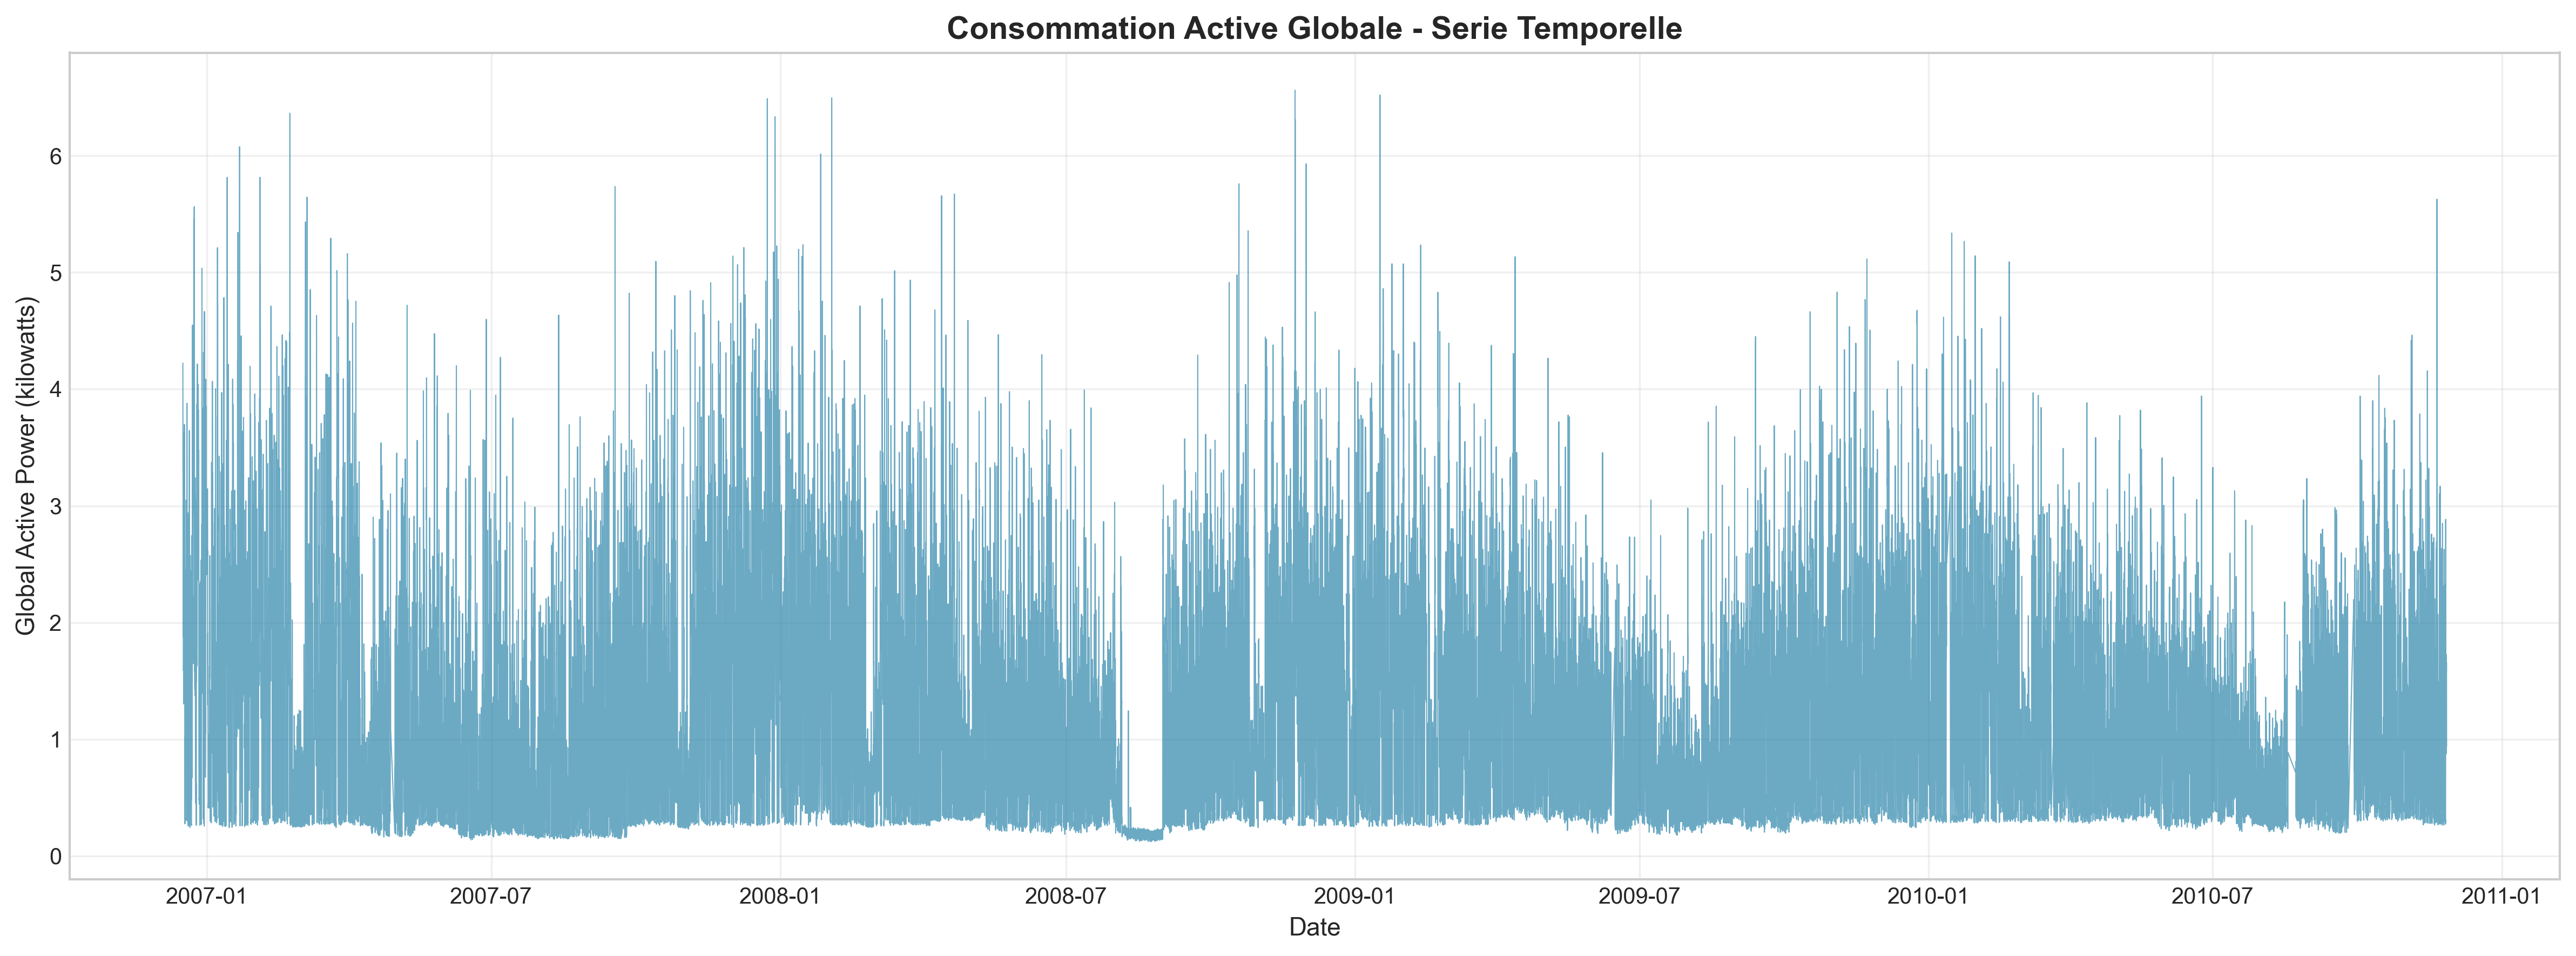

Figure 1 sauvegardee: d:\projet\Projet clustering\Projet household clustering\results\images\01_time_series.png


In [13]:
IMAGES_DIR = os.path.join(BASE_DIR, "results","images")
fig, ax = plt.subplots(figsize=(16, 6))
image_path = os.path.join(IMAGES_DIR, "01_time_series.png")
ax.plot(
    df_hourly['DateTime'],
    df_hourly['Global_active_power'],
    linewidth=0.5,
    alpha=0.7,
    color='#2E86AB'
)

ax.set_title('Consommation Active Globale - Serie Temporelle', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Global Active Power (kilowatts)', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 1 sauvegardee: {image_path}")

### Figure 2: Distributions des Variables Numeriques

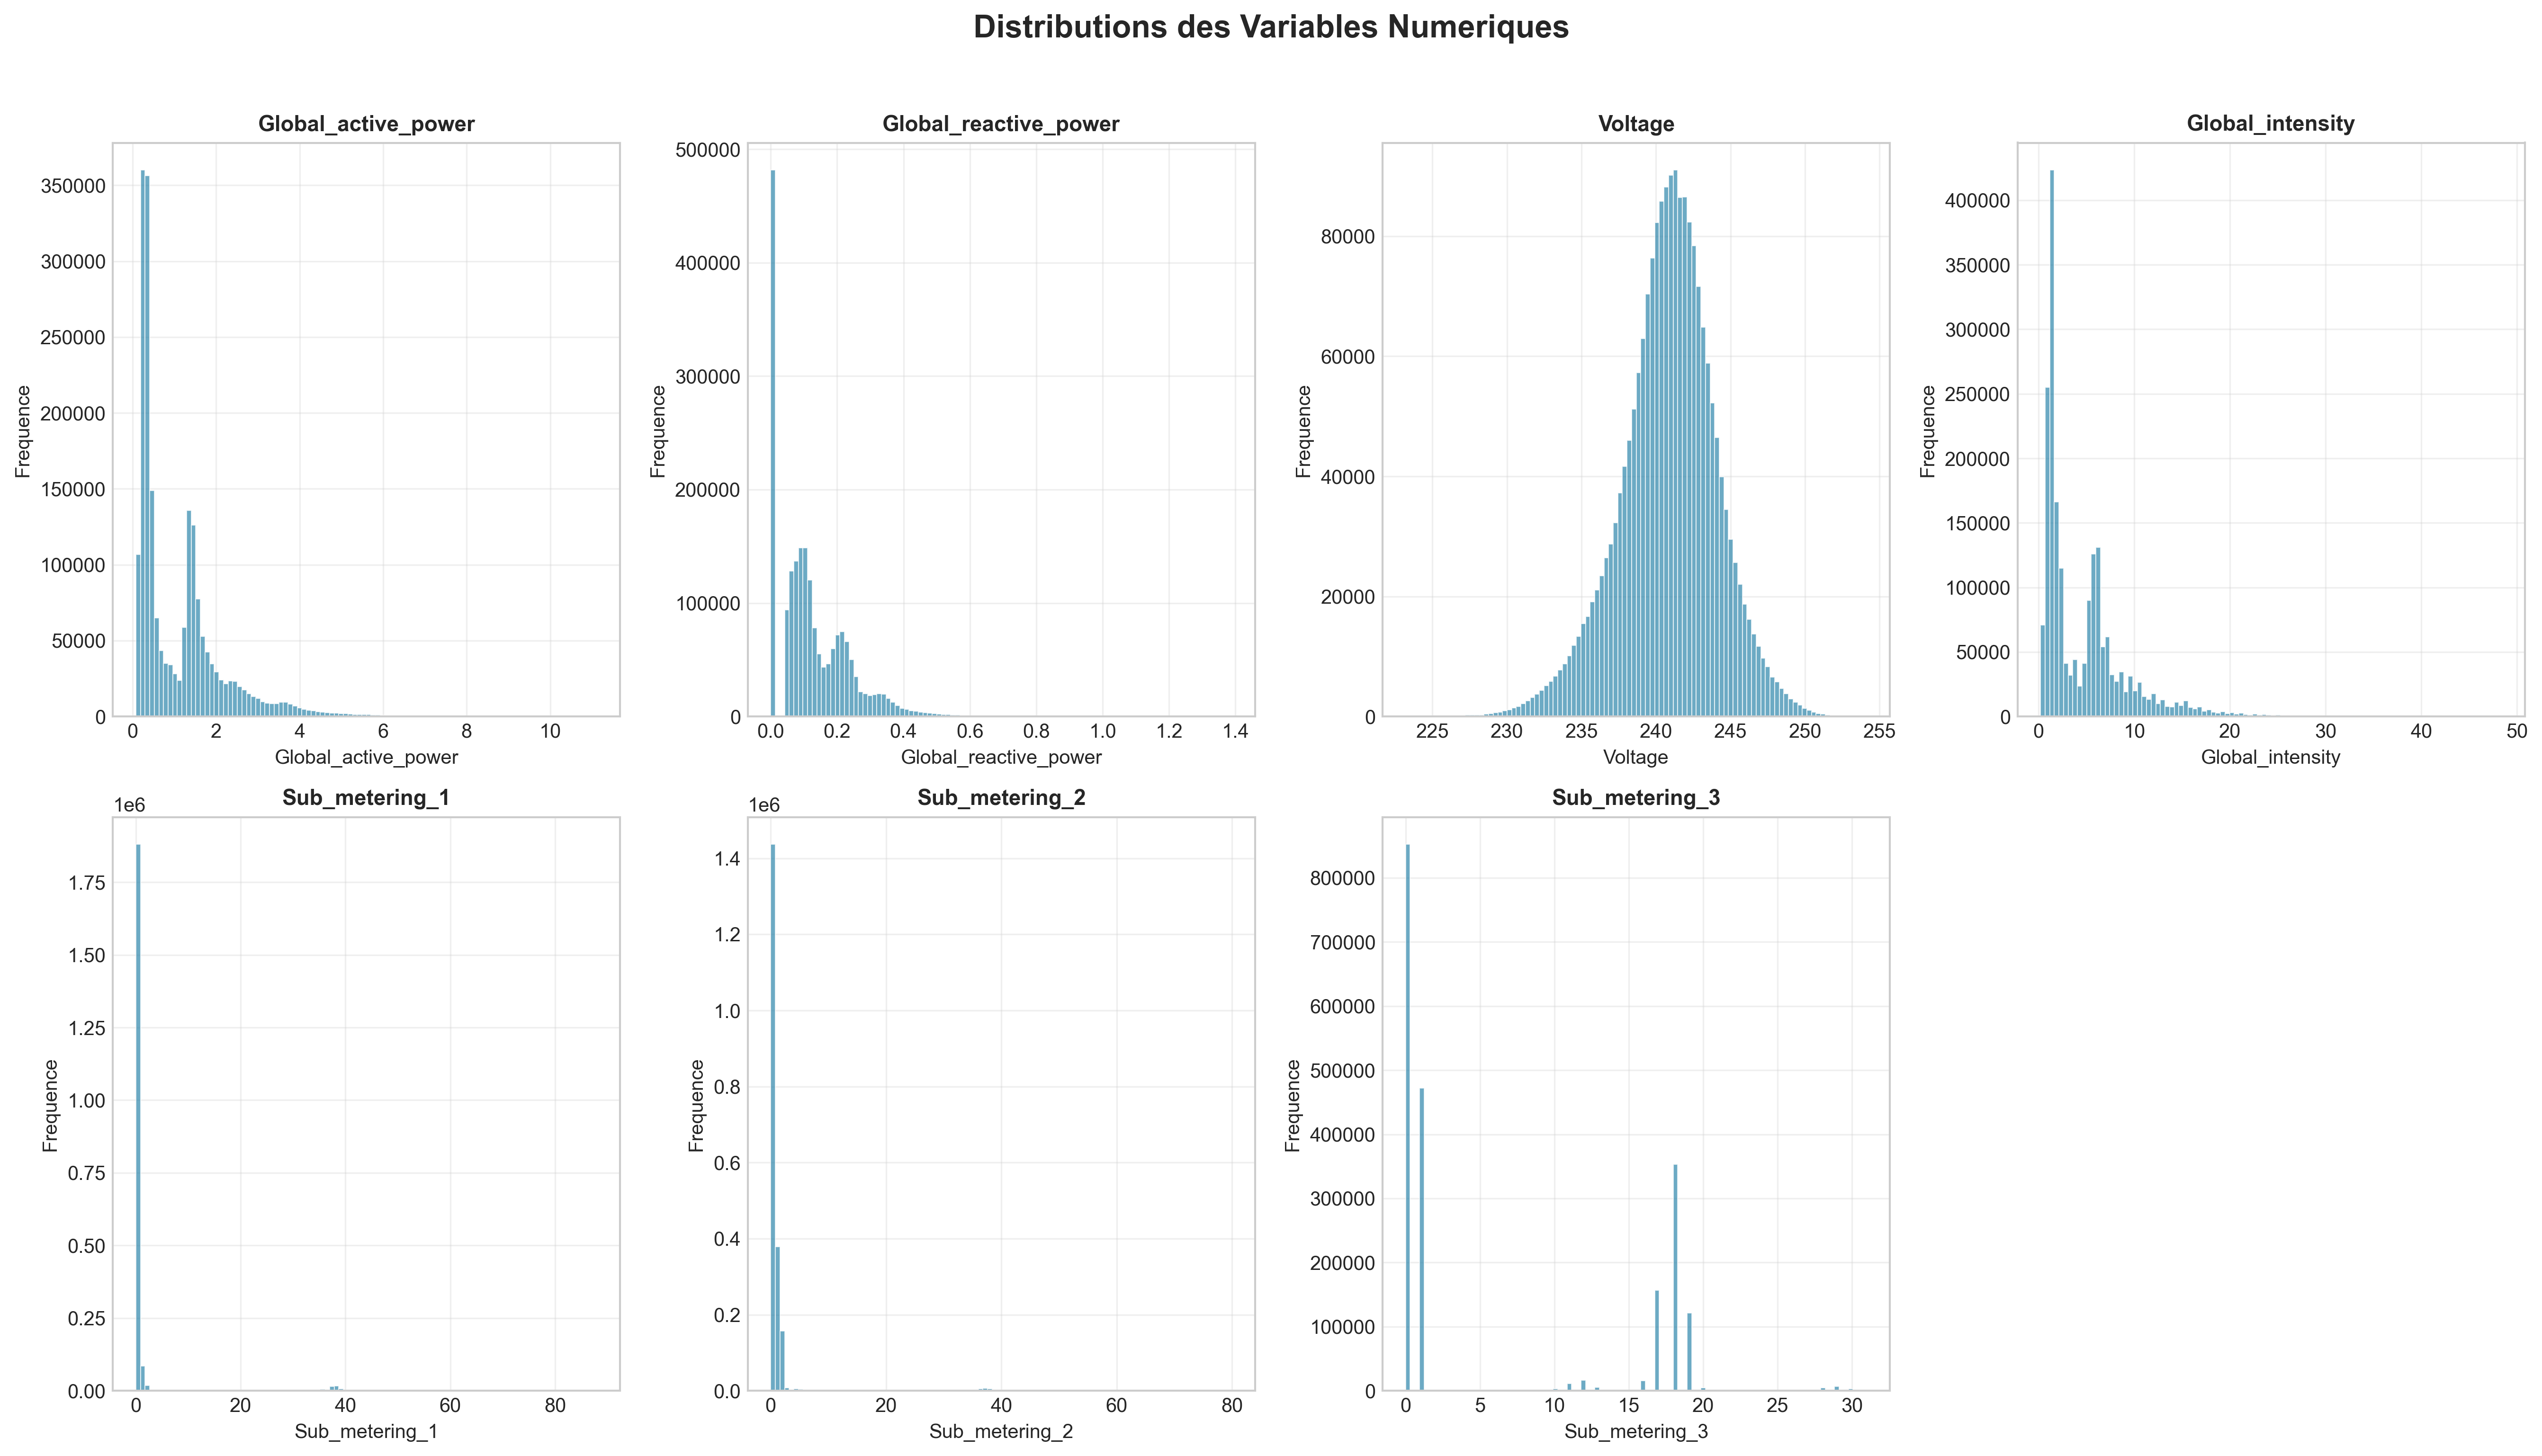

Figure 2 sauvegardee: d:\projet\Projet clustering\Projet household clustering\results\images\02_distributions.png


In [14]:

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()
image_path = os.path.join(IMAGES_DIR, "02_distributions.png")
for i, col in enumerate(numeric_cols):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=100, color='#2E86AB', alpha=0.7, edgecolor='white', linewidth=0.5)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequence')
    ax.grid(True, alpha=0.3)

fig.delaxes(axes[7])
fig.suptitle('Distributions des Variables Numeriques', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 2 sauvegardee: {image_path}")

### Figure 3: Boxplots (Detection d'Outliers)

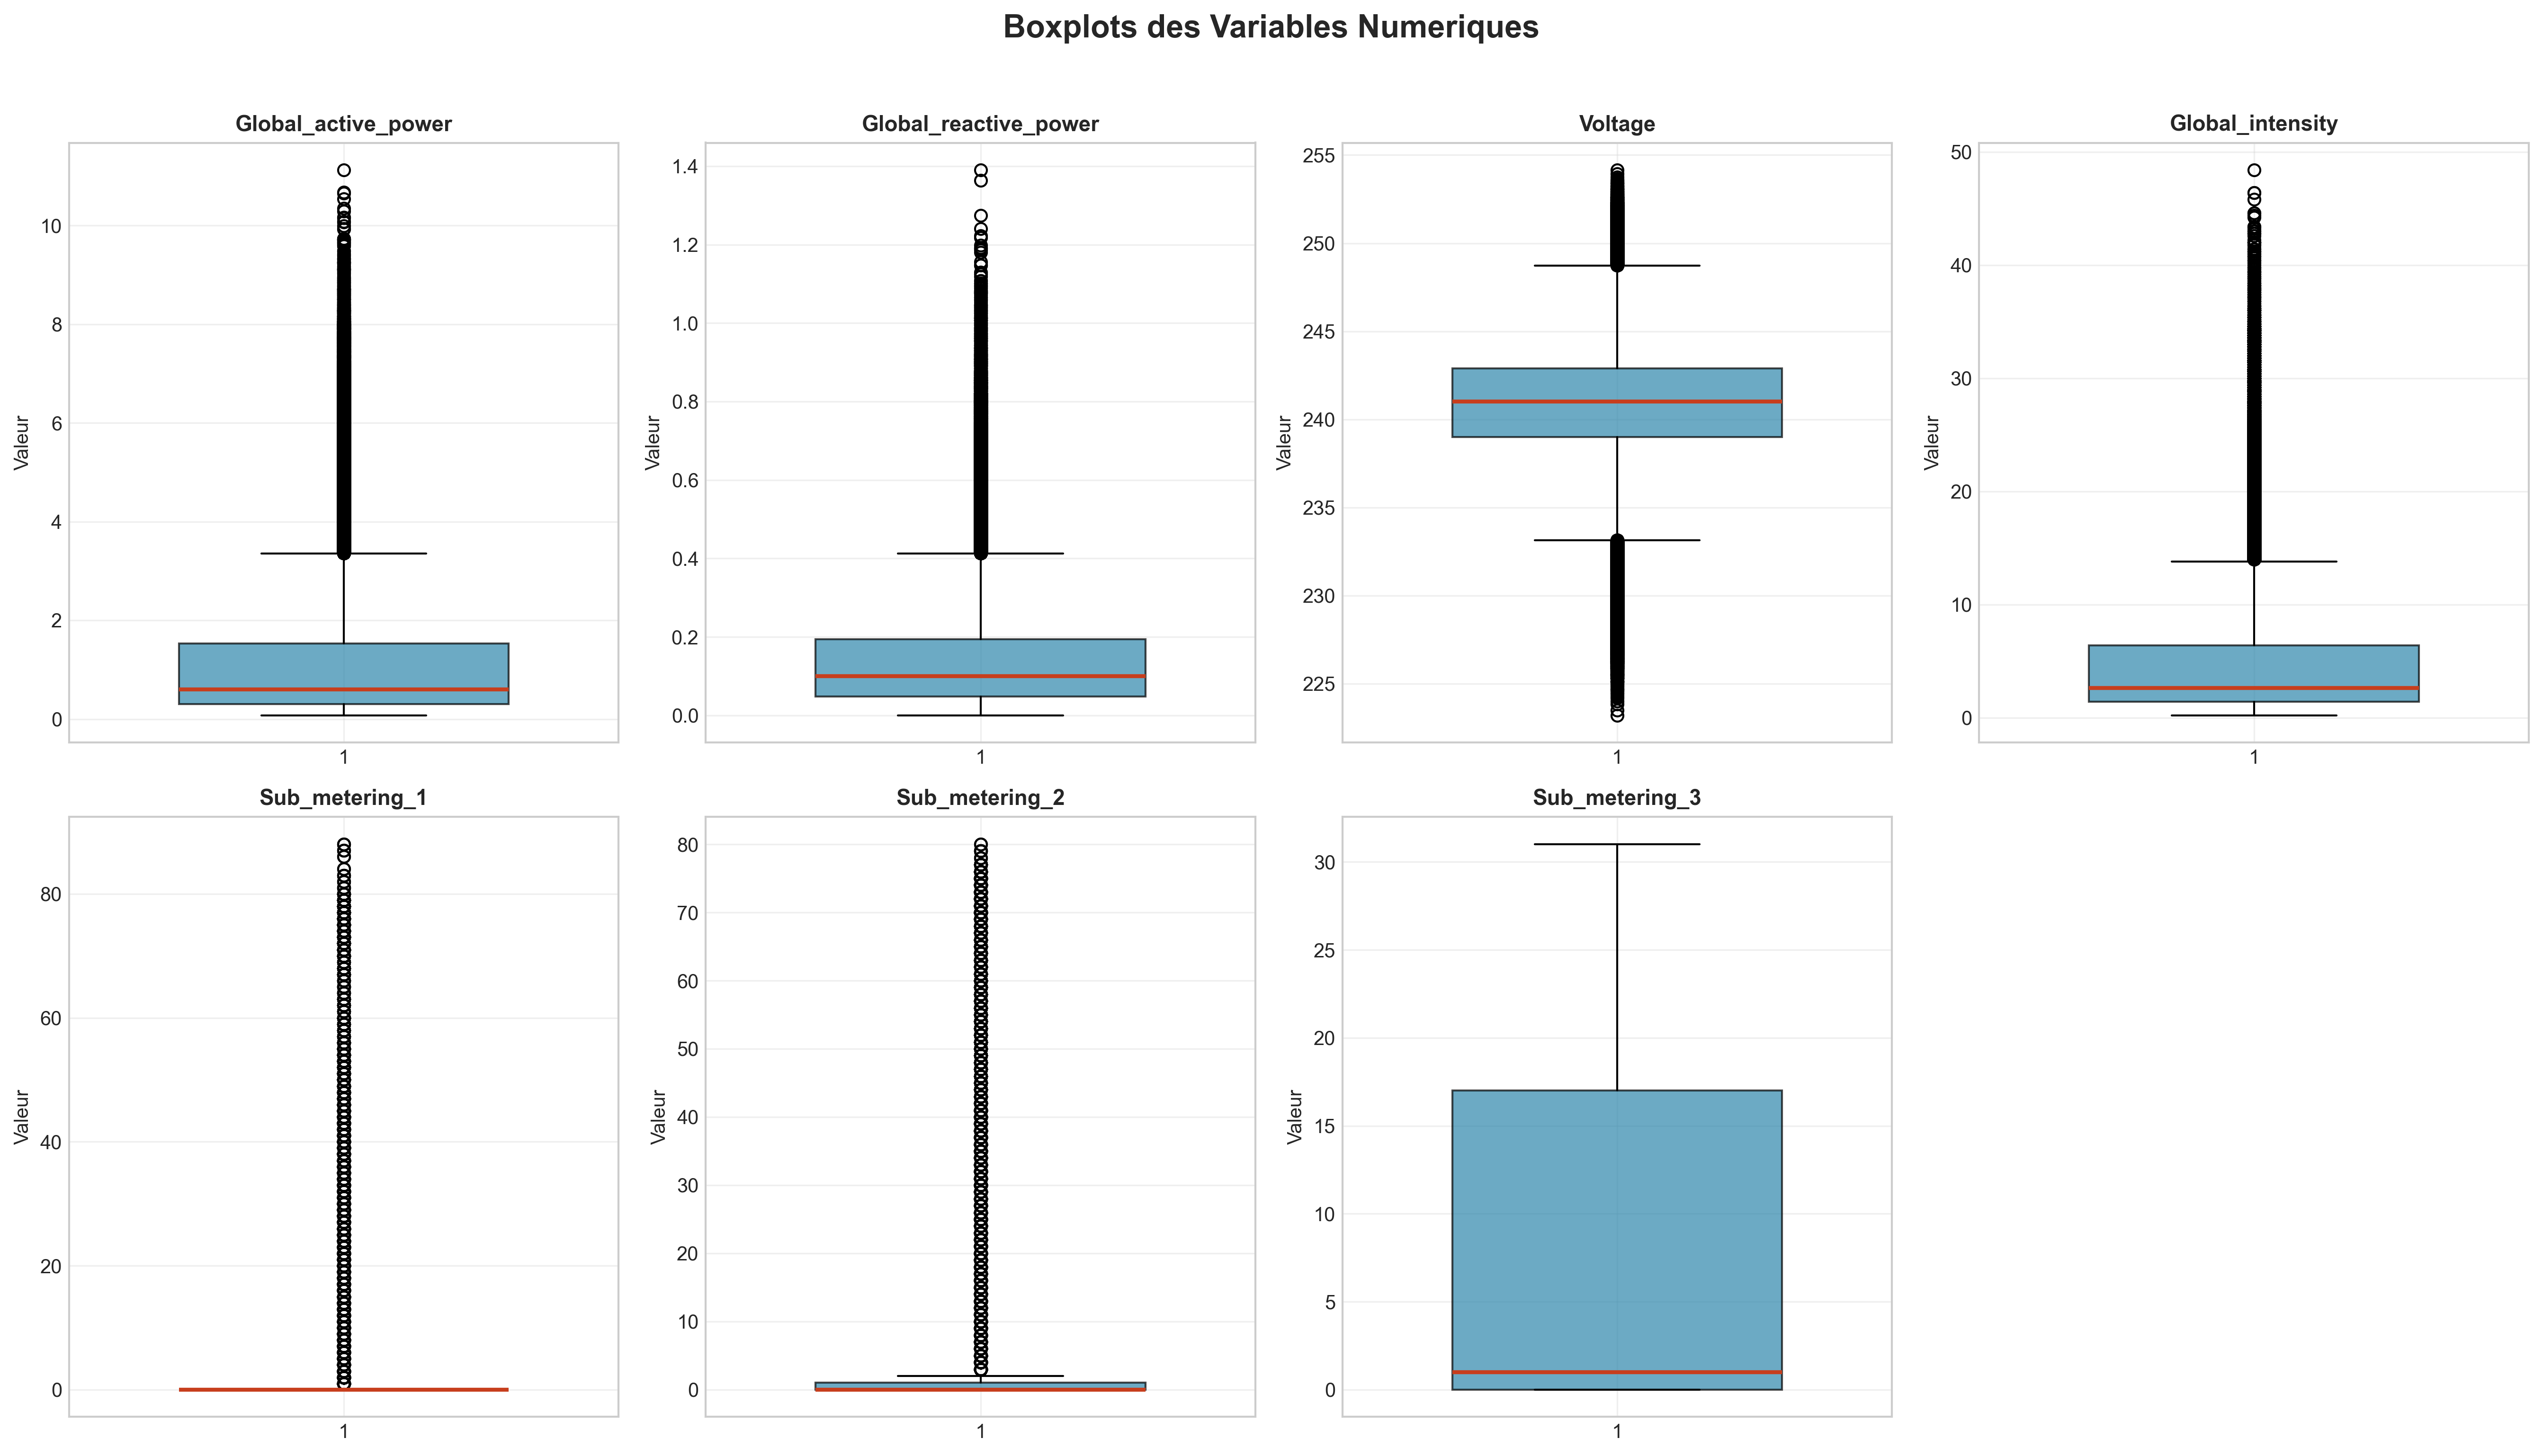

Figure 3 sauvegardee: d:\projet\Projet clustering\Projet household clustering\results\images\03_boxplots.png


In [15]:
image_path = os.path.join(IMAGES_DIR, "03_boxplots.png")
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    data = df[col].dropna()
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    bp['boxes'][0].set_facecolor('#2E86AB')
    bp['boxes'][0].set_alpha(0.7)
    bp['medians'][0].set_color('#C73E1D')
    bp['medians'][0].set_linewidth(2)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('Valeur')
    ax.grid(True, alpha=0.3)

fig.delaxes(axes[7])
fig.suptitle('Boxplots des Variables Numeriques', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 3 sauvegardee: {image_path}")

### Figure 4: Matrice de Correlation

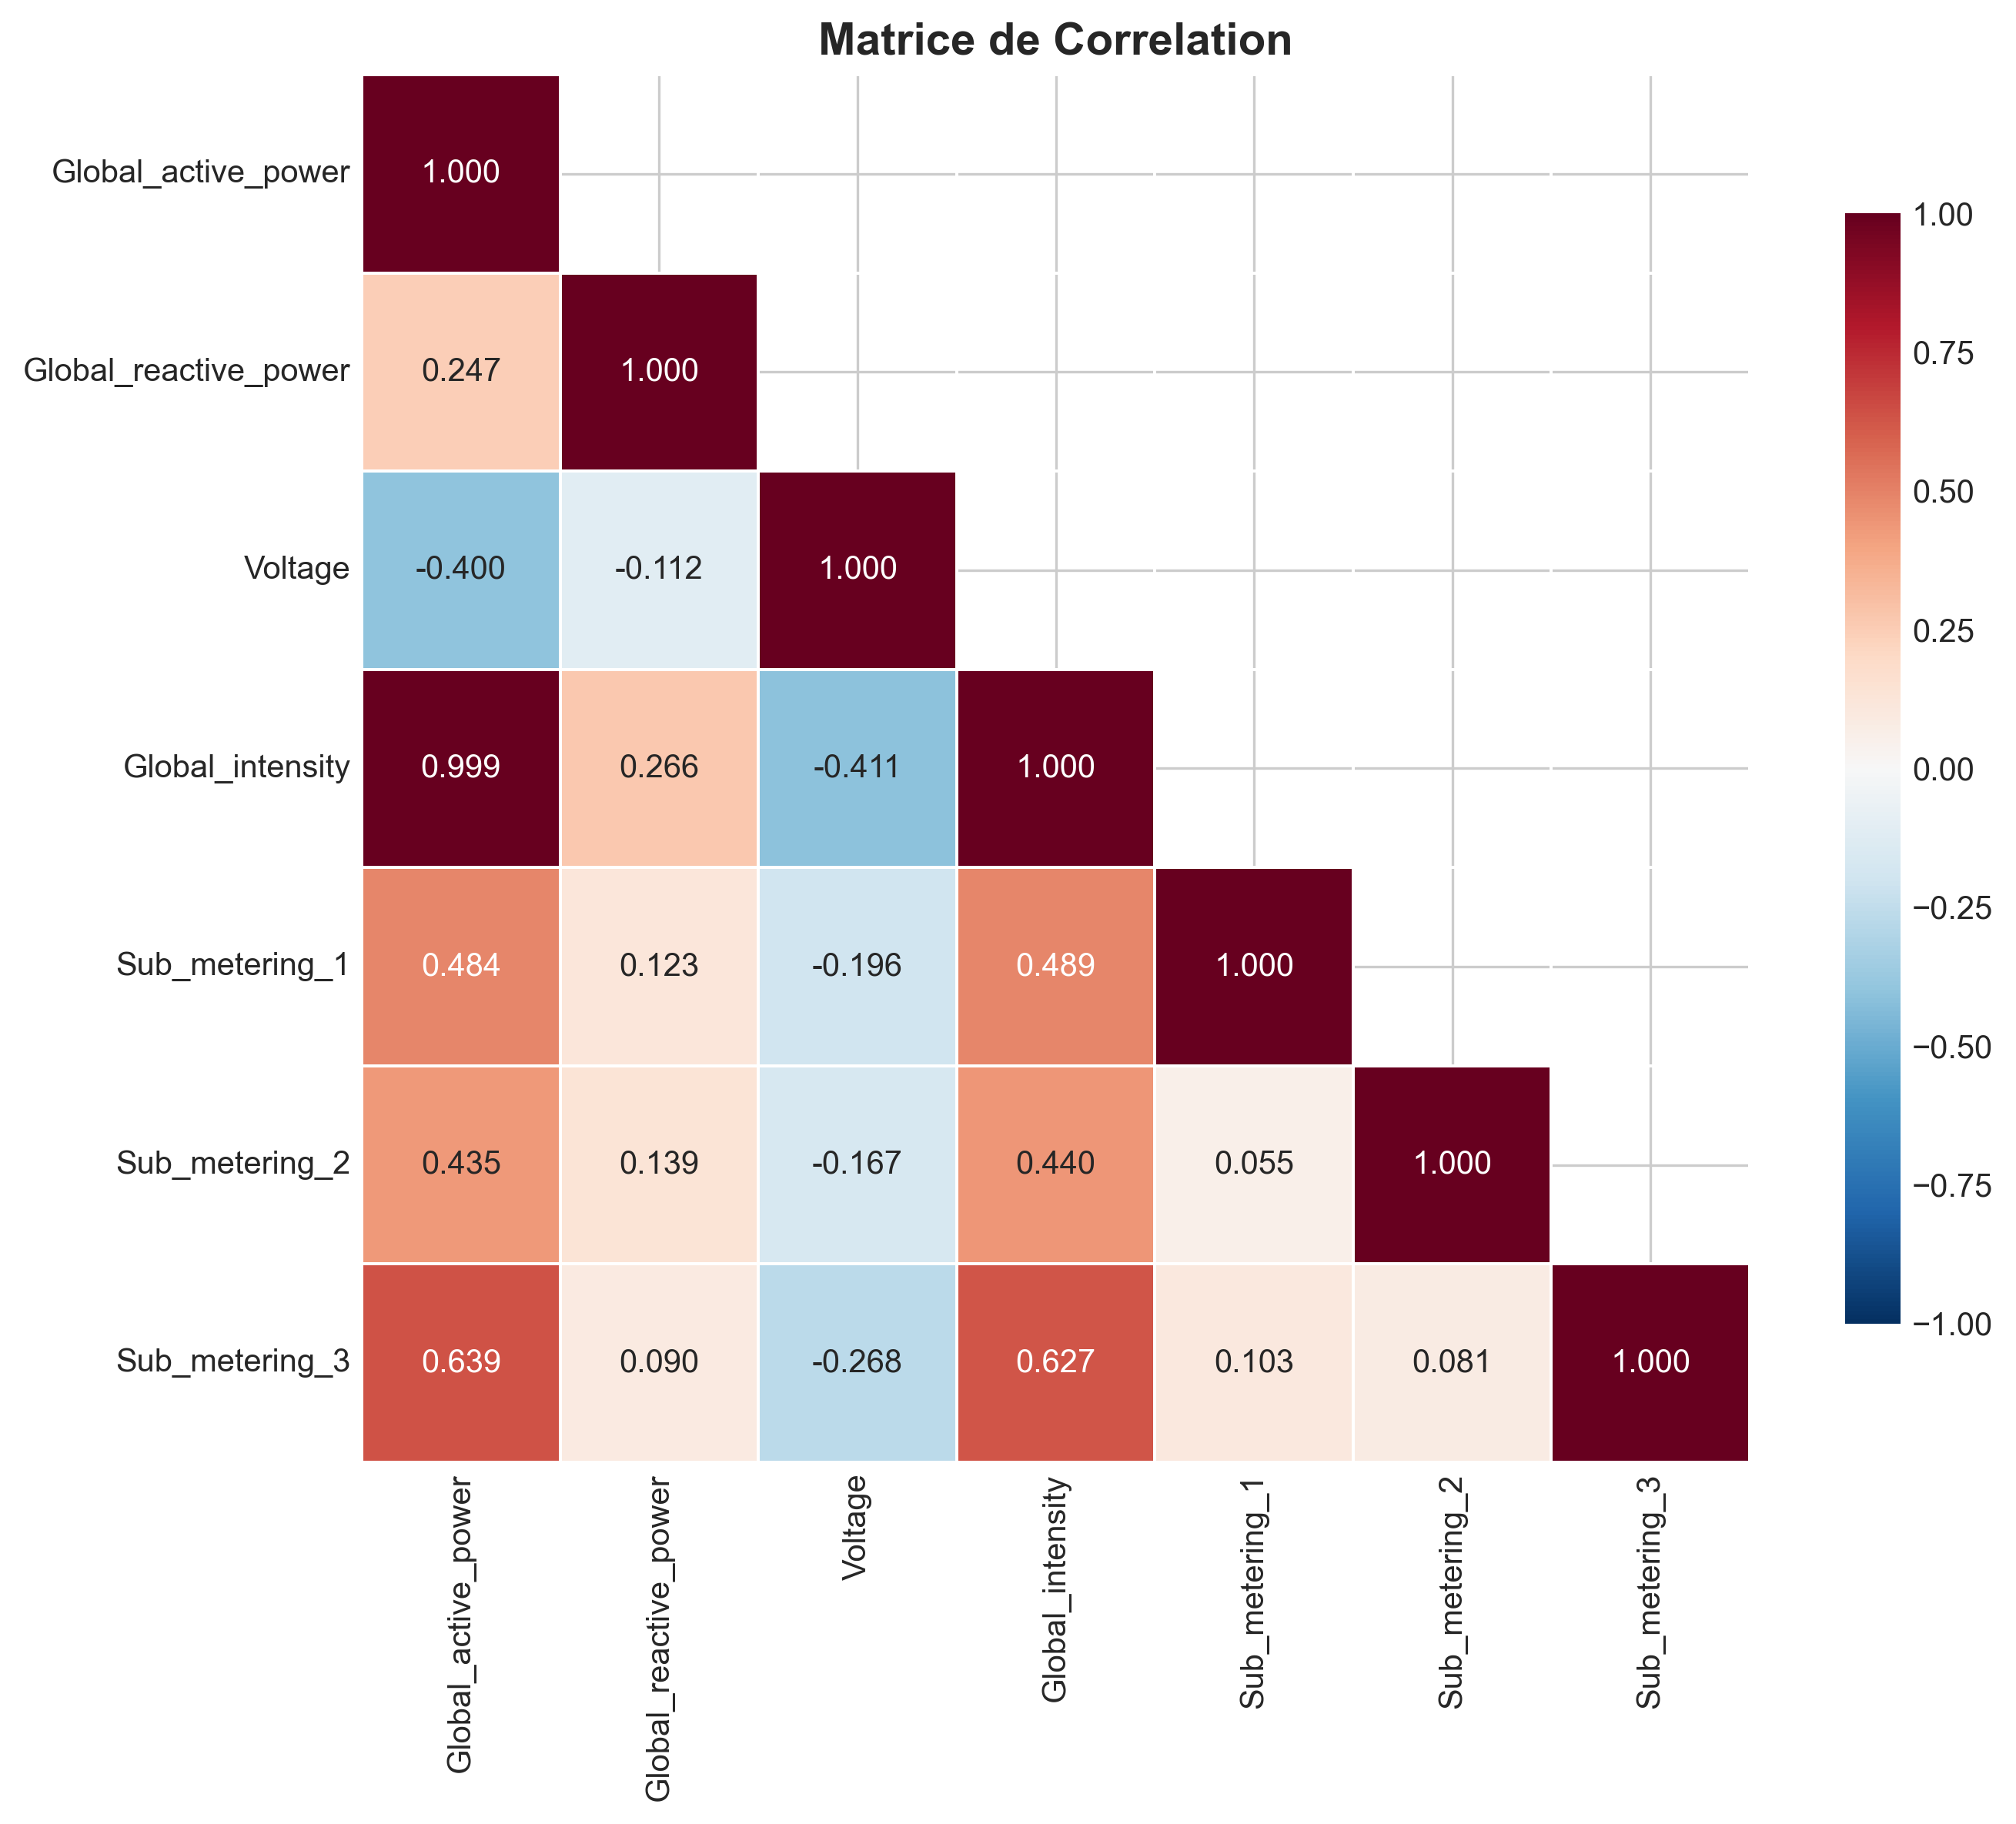

Figure 4 sauvegardée: d:\projet\Projet clustering\Projet household clustering\results\images\04_correlation_matrix.png


In [16]:
image_path = os.path.join(IMAGES_DIR, "04_correlation_matrix.png")
fig, ax = plt.subplots(figsize=(10, 8))

corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.3f',
    cmap='RdBu_r',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title('Matrice de Correlation', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 4 sauvegardée: {image_path}")

### Figure 5: Patterns Temporels (Mensuel, Horaire, Hebdomadaire, Annuel)

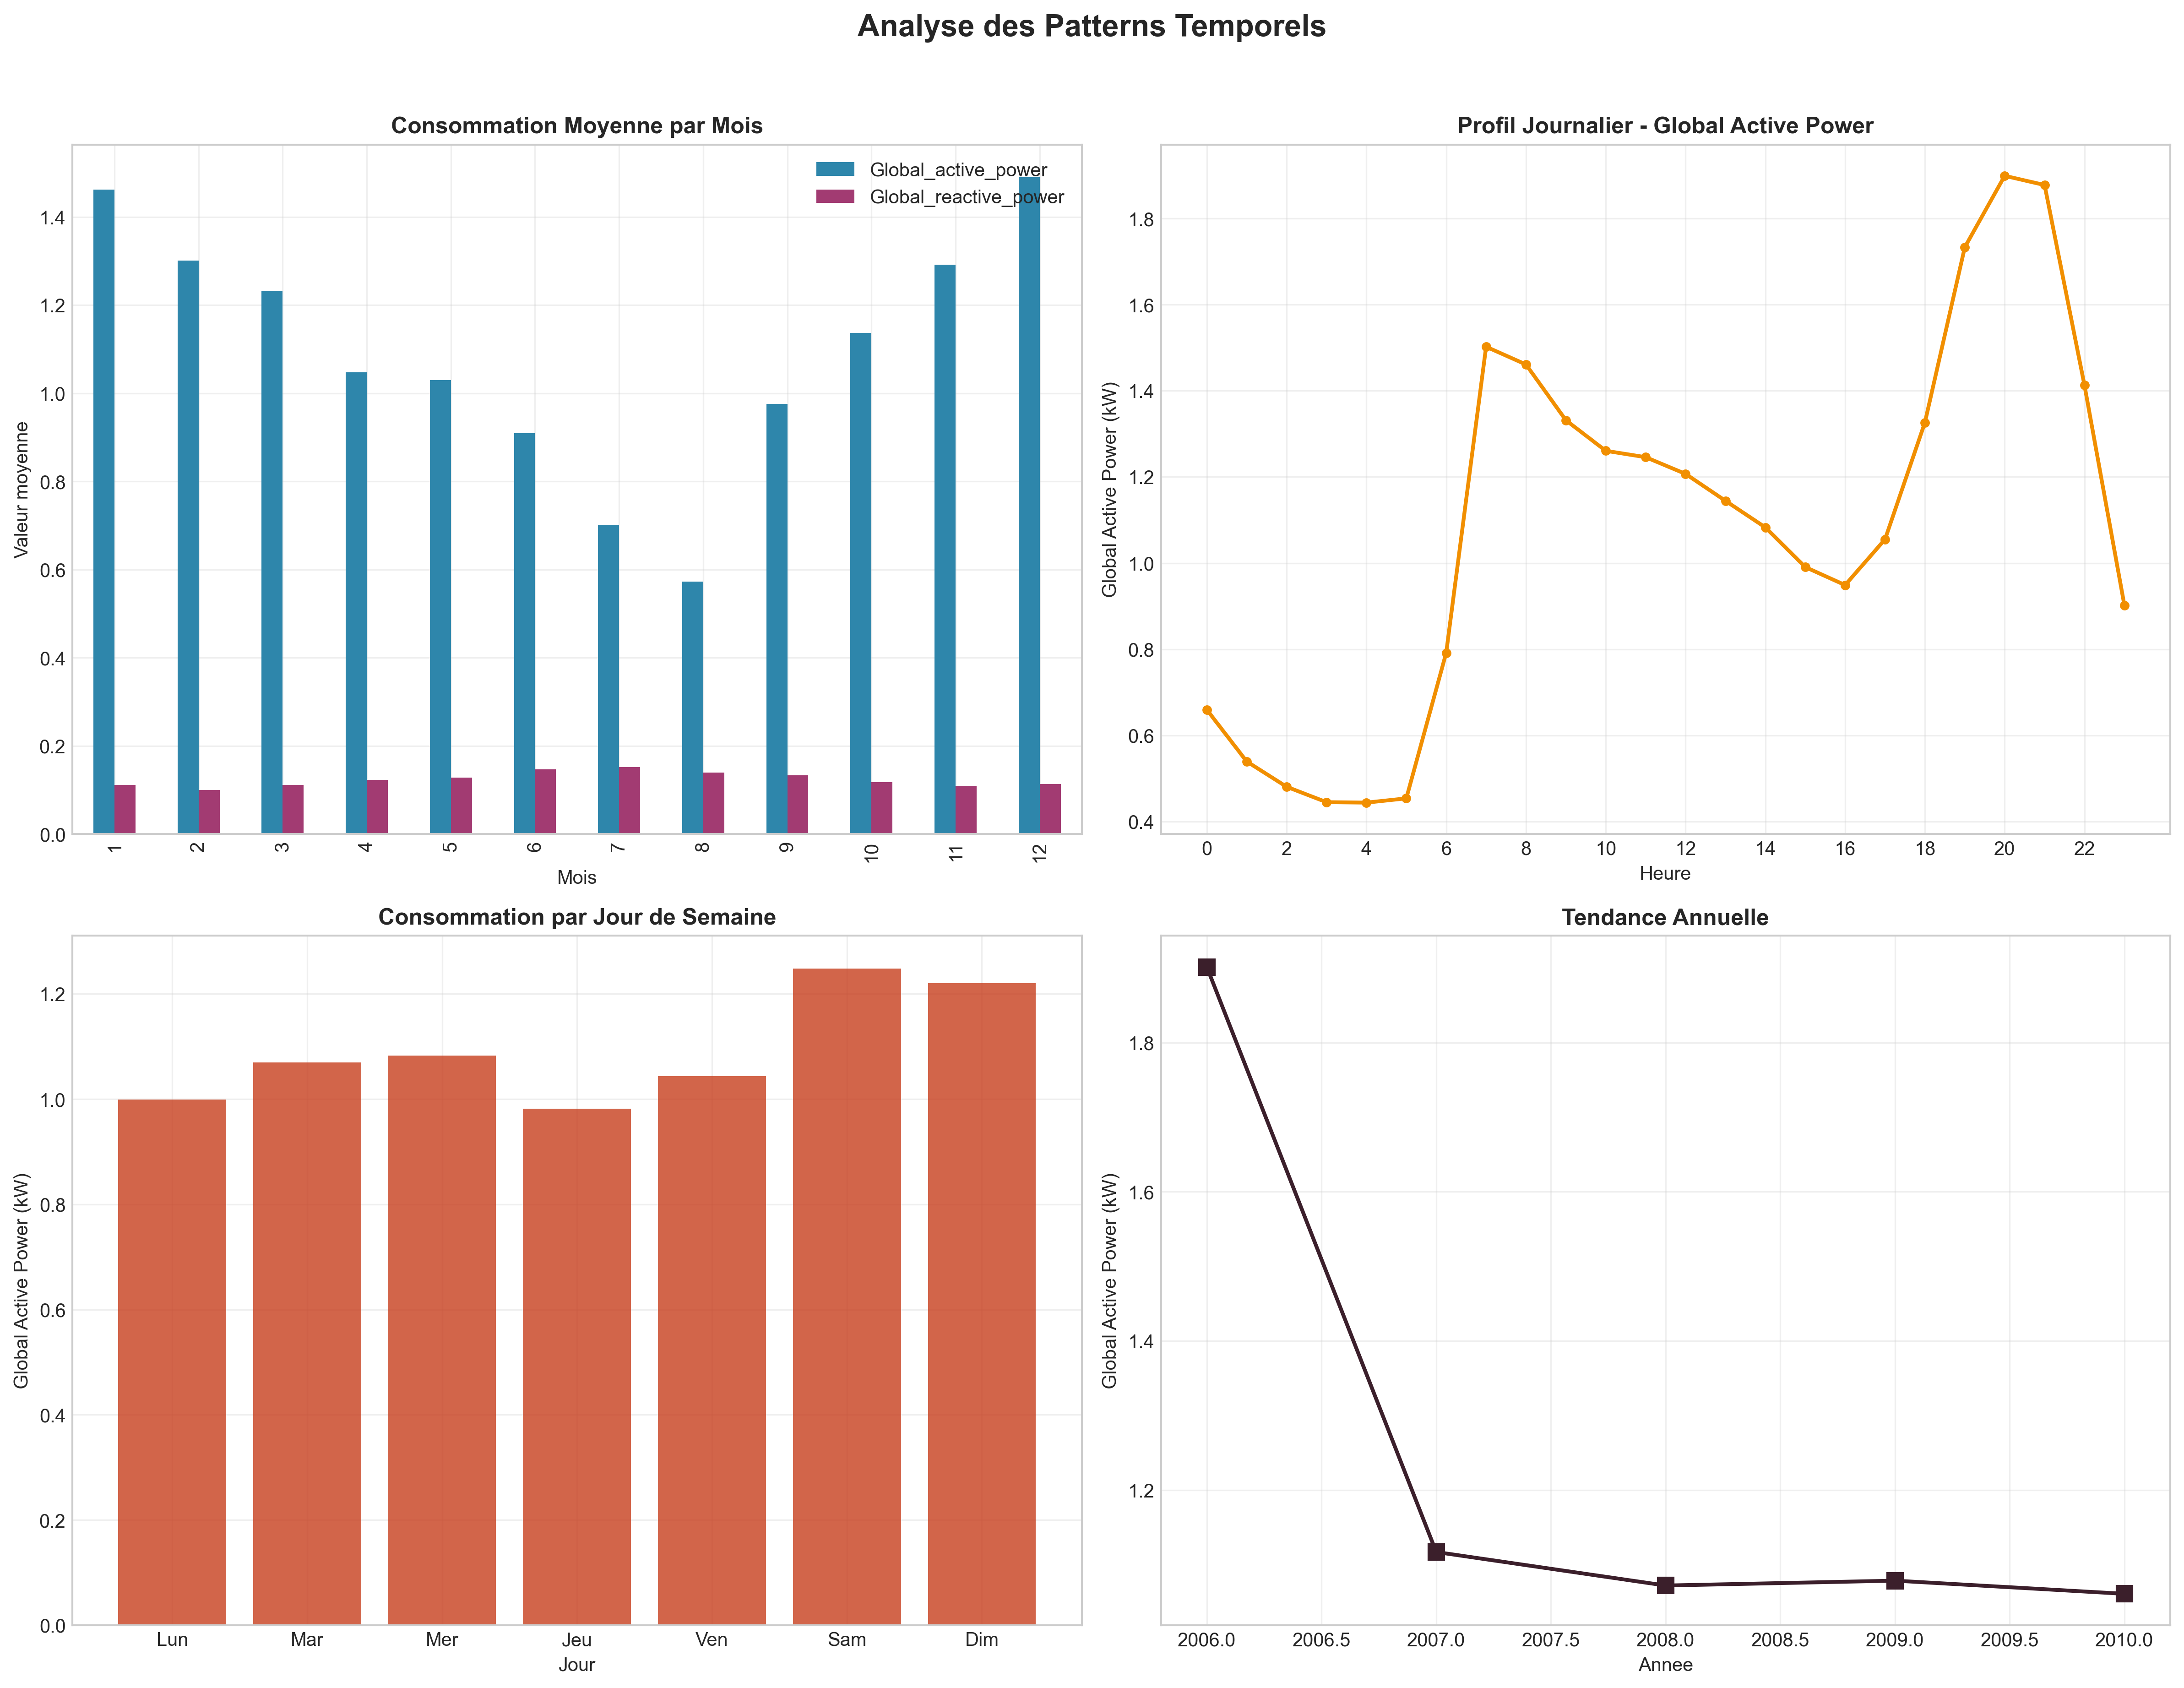

Figure 5 sauvegardée: d:\projet\Projet clustering\Projet household clustering\results\images\05_temporal_patterns.png


In [17]:
image_path = os.path.join(IMAGES_DIR, "05_temporal_patterns.png")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Monthly ---
ax1 = axes[0, 0]
monthly = df_viz.groupby('Month')[numeric_cols].mean()
monthly[['Global_active_power', 'Global_reactive_power']].plot(
    kind='bar', ax=ax1, color=['#2E86AB', '#A23B72']
)
ax1.set_title('Consommation Moyenne par Mois', fontweight='bold')
ax1.set_xlabel('Mois')
ax1.set_ylabel('Valeur moyenne')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# --- Hourly ---
ax2 = axes[0, 1]
hourly = df_viz.groupby('Hour')[numeric_cols].mean()
ax2.plot(
    hourly.index, hourly['Global_active_power'],
    marker='o', color='#F18F01', linewidth=2, markersize=4
)
ax2.set_title('Profil Journalier - Global Active Power', fontweight='bold')
ax2.set_xlabel('Heure')
ax2.set_ylabel('Global Active Power (kW)')
ax2.set_xticks(range(0, 24, 2))
ax2.grid(True, alpha=0.3)

# --- Weekly ---
ax3 = axes[1, 0]
weekly = df_viz.groupby('DayOfWeek')[numeric_cols].mean()
days = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']
ax3.bar(range(7), weekly['Global_active_power'], color='#C73E1D', alpha=0.8)
ax3.set_title('Consommation par Jour de Semaine', fontweight='bold')
ax3.set_xlabel('Jour')
ax3.set_ylabel('Global Active Power (kW)')
ax3.set_xticks(range(7))
ax3.set_xticklabels(days)
ax3.grid(True, alpha=0.3)

# --- Yearly ---
ax4 = axes[1, 1]
yearly = df_viz.groupby('Year')[numeric_cols].mean()
ax4.plot(
    yearly.index, yearly['Global_active_power'],
    marker='s', color='#3B1F2B', linewidth=2, markersize=8
)
ax4.set_title('Tendance Annuelle', fontweight='bold')
ax4.set_xlabel('Annee')
ax4.set_ylabel('Global Active Power (kW)')
ax4.grid(True, alpha=0.3)

plt.suptitle('Analyse des Patterns Temporels', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 5 sauvegardée: {image_path}")

### Figure 6: Analyse des Sub-meterings

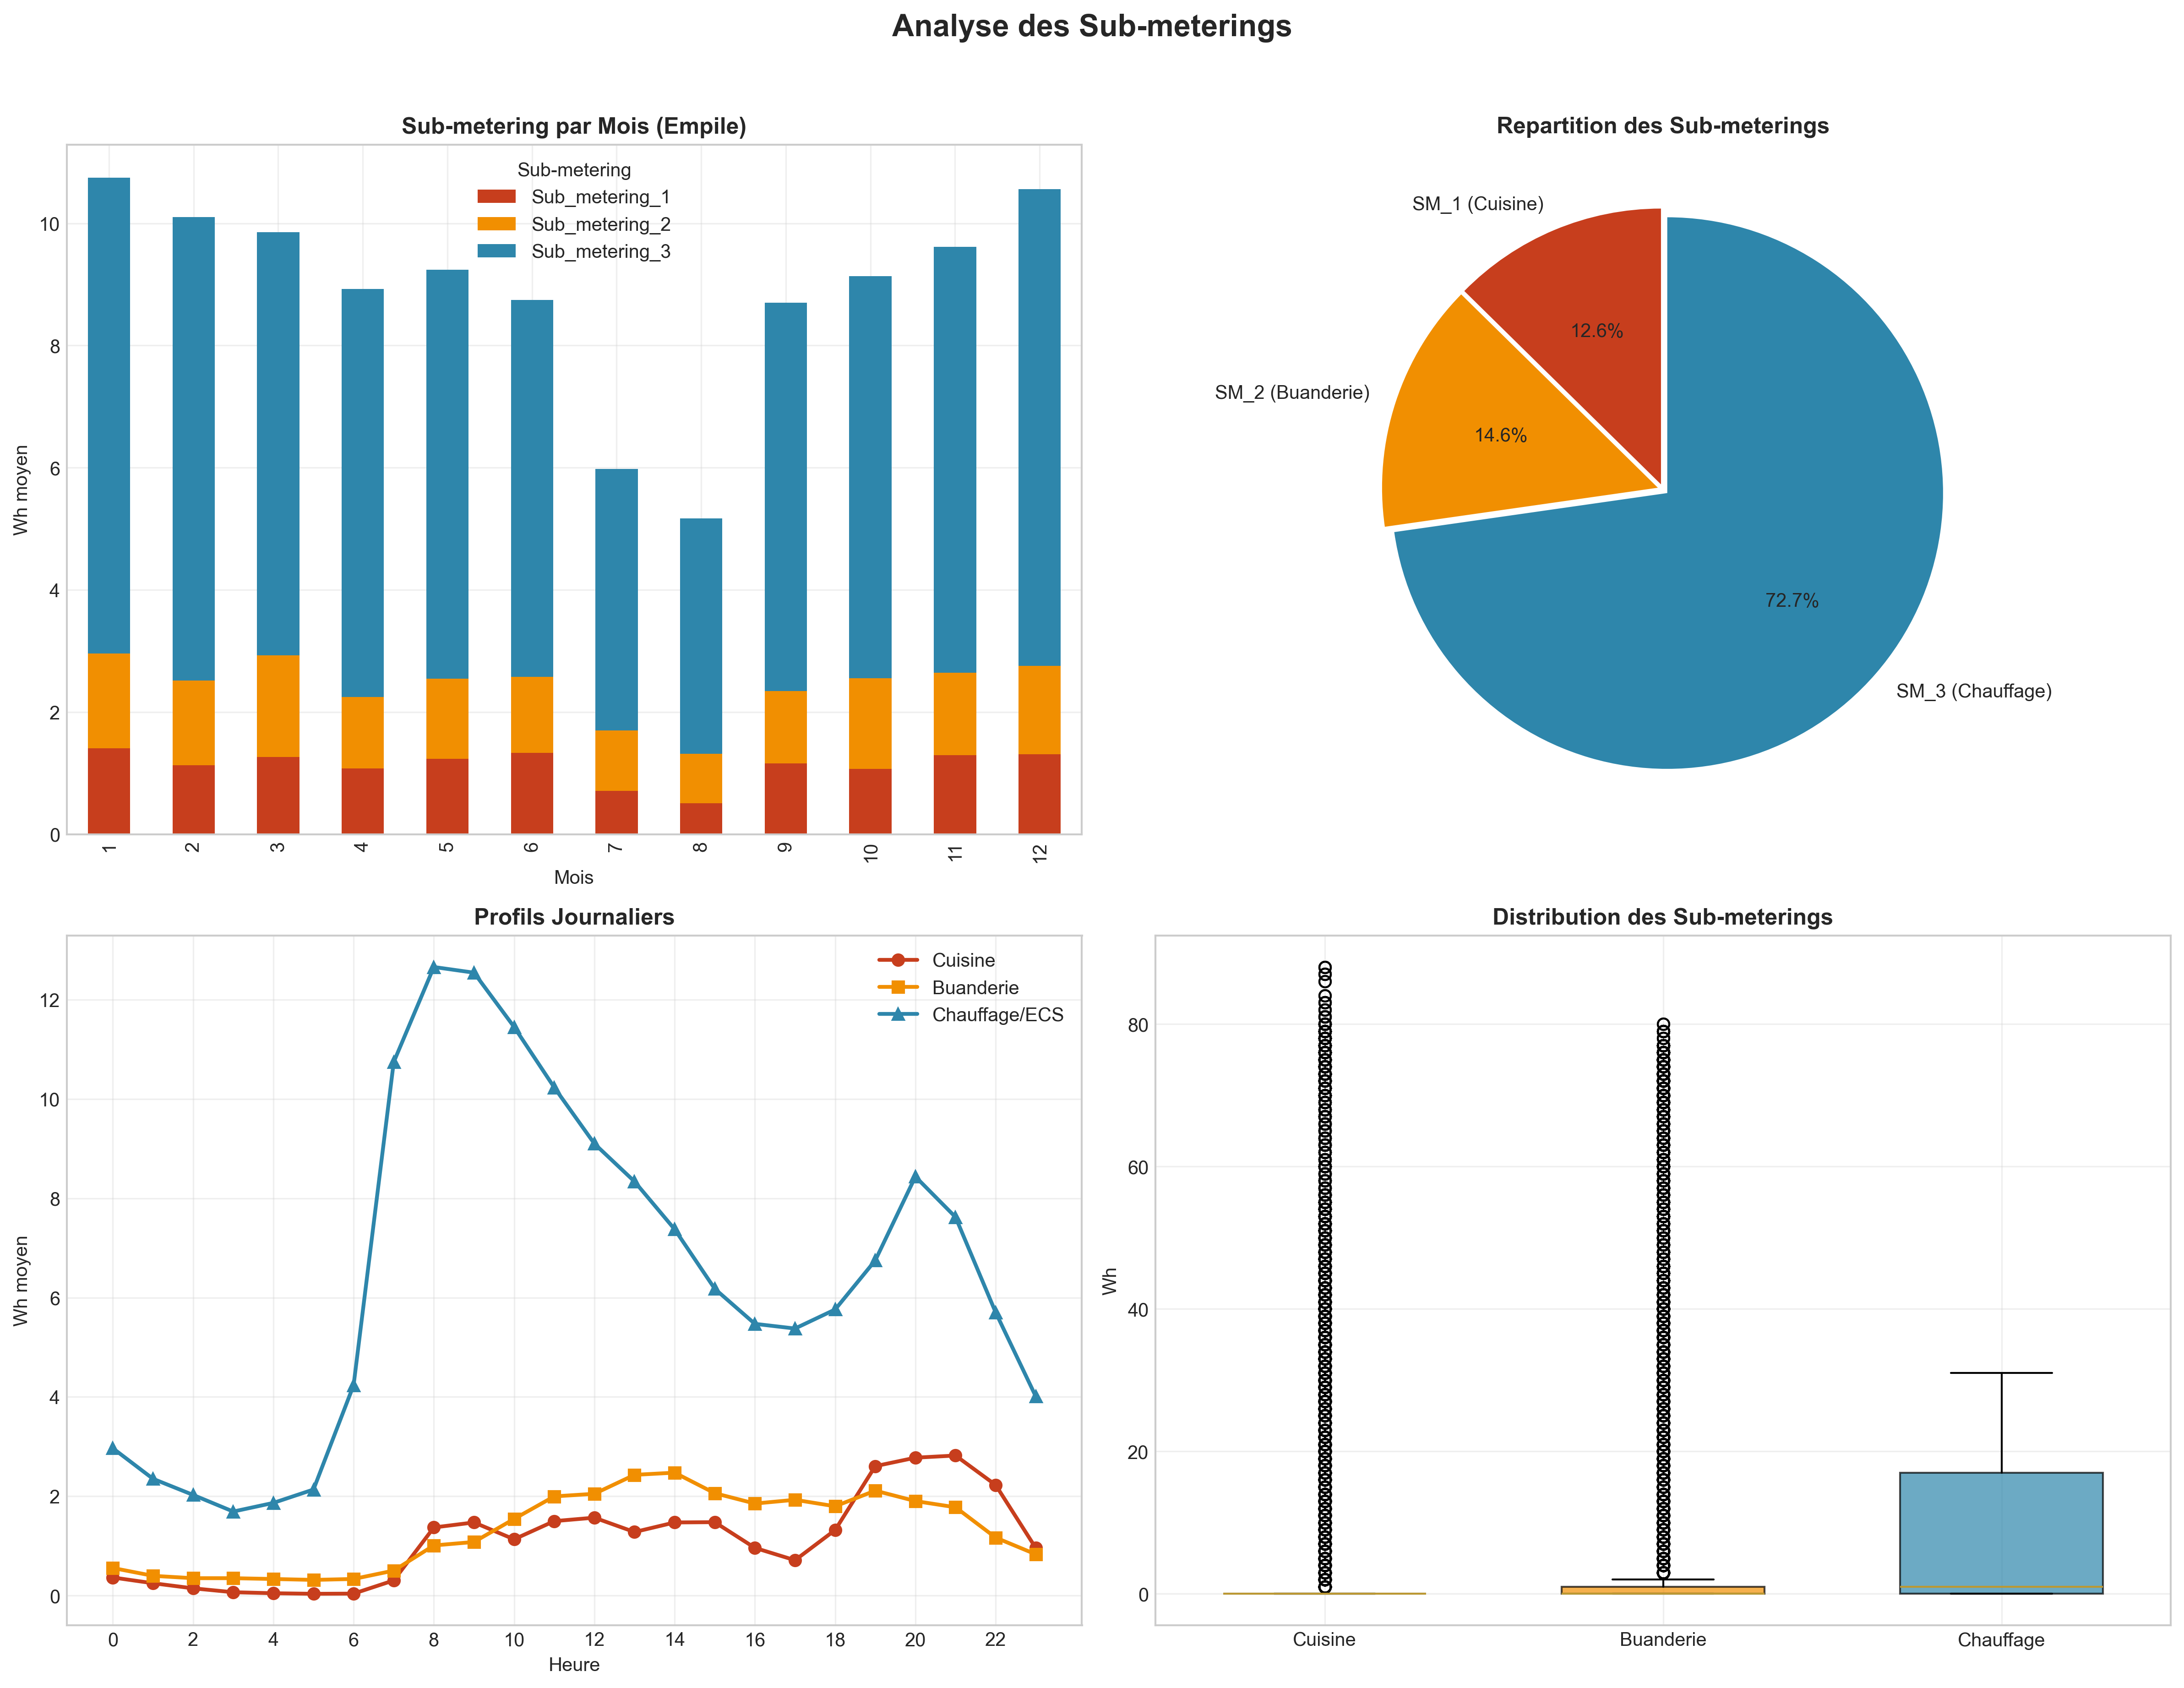

Figure 6 sauvegardée: d:\projet\Projet clustering\Projet household clustering\results\images\06_sub_metering_analysis.png


In [18]:
image_path = os.path.join(IMAGES_DIR, "06_sub_metering_analysis.png")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Monthly stacked ---
ax1 = axes[0, 0]
monthly_sub = df_viz.groupby('Month')[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].mean()
monthly_sub.plot(kind='bar', stacked=True, ax=ax1, color=['#C73E1D', '#F18F01', '#2E86AB'])
ax1.set_title('Sub-metering par Mois (Empile)', fontweight='bold')
ax1.set_xlabel('Mois')
ax1.set_ylabel('Wh moyen')
ax1.legend(title='Sub-metering')
ax1.grid(True, alpha=0.3)

# --- Pie chart ---
ax2 = axes[0, 1]
totals = df_viz[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].sum()
colors_pie = ['#C73E1D', '#F18F01', '#2E86AB']
ax2.pie(
    totals,
    labels=['SM_1 (Cuisine)', 'SM_2 (Buanderie)', 'SM_3 (Chauffage)'],
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    explode=(0.02, 0.02, 0.02)
)
ax2.set_title('Repartition des Sub-meterings', fontweight='bold')

# --- Hourly profiles ---
ax3 = axes[1, 0]
hourly_sub = df_viz.groupby('Hour')[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].mean()
ax3.plot(hourly_sub.index, hourly_sub['Sub_metering_1'], marker='o', label='Cuisine', color='#C73E1D', linewidth=2)
ax3.plot(hourly_sub.index, hourly_sub['Sub_metering_2'], marker='s', label='Buanderie', color='#F18F01', linewidth=2)
ax3.plot(hourly_sub.index, hourly_sub['Sub_metering_3'], marker='^', label='Chauffage/ECS', color='#2E86AB', linewidth=2)
ax3.set_title('Profils Journaliers', fontweight='bold')
ax3.set_xlabel('Heure')
ax3.set_ylabel('Wh moyen')
ax3.set_xticks(range(0, 24, 2))
ax3.legend()
ax3.grid(True, alpha=0.3)

# --- Boxplots ---
ax4 = axes[1, 1]
sub_data = [df_viz['Sub_metering_1'].dropna(), df_viz['Sub_metering_2'].dropna(), df_viz['Sub_metering_3'].dropna()]
bp = ax4.boxplot(sub_data, labels=['Cuisine', 'Buanderie', 'Chauffage'], patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], colors_pie):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax4.set_title('Distribution des Sub-meterings', fontweight='bold')
ax4.set_ylabel('Wh')
ax4.grid(True, alpha=0.3)

plt.suptitle('Analyse des Sub-meterings', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 6 sauvegardée: {image_path}")

## Etape 9: Creation du Dataset Propre

### Decisions de pretraitement:
| Probleme | Action | Justification |
|----------|--------|---------------|
| Valeurs manquantes (1.25%) | Suppression des lignes | Taux faible, pattern MCAR concomitant |
| Date/Time separes | Creation DateTime | Facilite les analyses |
| Doublons | Aucune action | 0 doublon detecte |
| Outliers | Conservation | Valeurs physiquement plausibles |

### Features creees:
- **Composantes temporelles:** Year, Month, Day, Hour, Minute, DayOfWeek, IsWeekend, Season
- **Physique:** Power_Factor (cos phi)

In [19]:

print("CREATION DU DATASET PROPRE")


df_clean = df.copy()

# 1. DateTime
df_clean['DateTime'] = pd.to_datetime(
    df_clean['Date'] + ' ' + df_clean['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

# 2. Supprimer les manquants
print(f"Avant nettoyage: {df_clean.shape[0]:,} lignes")
df_clean = df_clean.dropna(subset=numeric_cols)
print(f"Apres suppression manquants: {df_clean.shape[0]:,} lignes")

# 3. Supprimer doublons (si presents)
df_clean = df_clean.drop_duplicates(subset=['DateTime'])
print(f"Apres suppression doublons: {df_clean.shape[0]:,} lignes")

# 4. Trier
df_clean = df_clean.sort_values('DateTime').reset_index(drop=True)

# 5. Features temporelles
df_clean['Year'] = df_clean['DateTime'].dt.year
df_clean['Month'] = df_clean['DateTime'].dt.month
df_clean['Day'] = df_clean['DateTime'].dt.day
df_clean['Hour'] = df_clean['DateTime'].dt.hour
df_clean['Minute'] = df_clean['DateTime'].dt.minute
df_clean['DayOfWeek'] = df_clean['DateTime'].dt.dayofweek
df_clean['IsWeekend'] = df_clean['DayOfWeek'].isin([5, 6]).astype(int)

season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}
df_clean['Season'] = df_clean['Month'].map(season_map)

# 6. Power Factor
df_clean['Power_Factor'] = df_clean['Global_active_power'] / np.sqrt(
    df_clean['Global_active_power']**2 + df_clean['Global_reactive_power']**2
)
df_clean['Power_Factor'] = df_clean['Power_Factor'].fillna(0)

# 7. Reordonner
cols_order = [
    'DateTime', 'Date', 'Time',
    'Year', 'Month', 'Day', 'Hour', 'Minute',
    'DayOfWeek', 'IsWeekend', 'Season',
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Power_Factor',
    'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'
]
df_clean = df_clean[cols_order]

print(f"--- DATASET PROPRE FINAL ---")
print(f"Dimensions: {df_clean.shape[0]:,} lignes x {df_clean.shape[1]} colonnes")
print(f"Periode: {df_clean['DateTime'].min()} au {df_clean['DateTime'].max()}")
print(f"Valeurs manquantes: {df_clean.isnull().sum().sum()}")
print(f"Colonnes: {df_clean.columns.tolist()}")

CREATION DU DATASET PROPRE
Avant nettoyage: 2,075,259 lignes
Apres suppression manquants: 2,049,280 lignes
Apres suppression doublons: 2,049,280 lignes
--- DATASET PROPRE FINAL ---
Dimensions: 2,049,280 lignes x 19 colonnes
Periode: 2006-12-16 17:24:00 au 2010-11-26 21:02:00
Valeurs manquantes: 0
Colonnes: ['DateTime', 'Date', 'Time', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'IsWeekend', 'Season', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Power_Factor', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


### Sauvegarde du dataset propre

In [20]:
PROCESSED_DIR = os.path.join(BASE_DIR, "data","processed")
# Sauvegarder le dataset complet
df_clean.to_csv(os.path.join(PROCESSED_DIR, 'household_power_consumption_cleaned.csv'), index=False)
print("Dataset propre sauvegarde: household_power_consumption_cleaned.csv")

# Sauvegarder un echantillon
#df_clean.head(10000).to_csv(os.path.join(PROCESSED_DIR, 'household_power_consumption_sample.csv'), index=False)
#print("Echantillon (10k lignes): household_power_consumption_sample.csv")


Dataset propre sauvegarde: household_power_consumption_cleaned.csv


## Etape 10: Resume Final

In [21]:
print("=" * 70)
print("  PIPELINE EDA TERMINE AVEC SUCCES")
print("=" * 70)

print("\n  Fichiers produits:")
print("    - 01_time_series.png          -> Serie temporelle")
print("    - 02_distributions.png        -> Distributions")
print("    - 03_boxplots.png             -> Boxplots")
print("    - 04_correlation_matrix.png   -> Correlation")
print("    - 05_temporal_patterns.png    -> Patterns temporels")
print("    - 06_sub_metering_analysis.png -> Sub-meterings")
print("    - household_power_consumption_clean.csv -> Dataset propre")
print("    - household_power_consumption_sample.csv -> Echantillon 10k")
print("    - household_power_consumption_2006-2007.csv -> Dataset 1 an")

print("\n  Dataset propre:")
print(f"    Lignes:    {df_clean.shape[0]:,}")
print(f"    Colonnes:  {df_clean.shape[1]}")
print(f"    Manquants: {df_clean.isnull().sum().sum()}")
print(f"    Periode:   {df_clean['DateTime'].min()} au {df_clean['DateTime'].max()}")

print("\n  Principales conclusions:")
print("    - 1.25% de valeurs manquantes (pattern concomitant, pannes equipement)")
print("    - 0 doublon detecte")
print("    - Outliers conserves (valeurs physiquement plausibles)")
print("    - Forte saisonnalite hiver/ete (rapport 2.5:1)")
print("    - Profil journalier bimodal (pics 7-8h et 19-21h)")
print("    - Chauffage/ECS = 72.7% de la consommation mesuree")
print("    - Correlation parfaite (0.999) entre P_active et Intensite")

print("=" * 70)

  PIPELINE EDA TERMINE AVEC SUCCES

  Fichiers produits:
    - 01_time_series.png          -> Serie temporelle
    - 02_distributions.png        -> Distributions
    - 03_boxplots.png             -> Boxplots
    - 04_correlation_matrix.png   -> Correlation
    - 05_temporal_patterns.png    -> Patterns temporels
    - 06_sub_metering_analysis.png -> Sub-meterings
    - household_power_consumption_clean.csv -> Dataset propre
    - household_power_consumption_sample.csv -> Echantillon 10k
    - household_power_consumption_2006-2007.csv -> Dataset 1 an

  Dataset propre:
    Lignes:    2,049,280
    Colonnes:  19
    Manquants: 0
    Periode:   2006-12-16 17:24:00 au 2010-11-26 21:02:00

  Principales conclusions:
    - 1.25% de valeurs manquantes (pattern concomitant, pannes equipement)
    - 0 doublon detecte
    - Outliers conserves (valeurs physiquement plausibles)
    - Forte saisonnalite hiver/ete (rapport 2.5:1)
    - Profil journalier bimodal (pics 7-8h et 19-21h)
    - Chauffage/E